<div dir="rtl" style="font-family:Cairo,Tahoma,sans-serif;text-align:right;line-height:1.65;border-radius:18px;border:1px solid #cde4e7;padding:22px;background:#eff8f9">

# 🏥 نموذج التنبؤ بالوصول إلى المستشفيات في اليمن
### دليل عرض ومناقشة تجربة **EXP_0012** — خطوة بخطوة

**Yemen Hospital Accessibility Prediction Model | Presentation & Walkthrough**

**إعداد وتطوير:** المهندس وهيب أمين عبد الجليل أحمد سعد  
**الإشراف العلمي:** أ.د. خالد الحسيني  
**البرنامج:** برنامج إعداد مهندسي الذكاء الاصطناعي  
**الجهة:** مركز تطوير التعليم التقني والبحث العلمي – ذمار

> **الرسالة الإنسانية:** نستخدم تعلم الآلة لدراسة تفاوت إمكانية الوصول إلى المستشفيات بين مديريات اليمن، وإظهار الفجوات بصورة بحثية قابلة للفهم، لا لاتخاذ قرارات علاجية مباشرة.

**ما يميز هذا الدفتر:** شروح قصيرة جاهزة للإلقاء، كود حقيقي من التجربة، رسوم وجداول، أسئلة مناقشة، وتجربة مباشرة لتغيير المدخلات.

**تنبيه علمي:** الهدف هو **مؤشر GAIA النموذجي لعام 2030** لنسبة من يمكنهم الوصول إلى مستشفى خلال 60 دقيقة؛ وليس قياسًا ميدانيًا مباشرًا لعام 2030. ونتائج EXP_0012 **استكشافية** ولا تُعد اختبارًا خارجيًا مستقلًا جديدًا.

</div>


<div dir="rtl" style="text-align:right;line-height:1.75">

## 🎬 كيف أقدّم المشروع في أول دقيقة؟

> «هذا المشروع يدرس مشكلة إنسانية في اليمن: تفاوت الوصول إلى المستشفيات بين المديريات. استخدمنا بيانات مجمّعة لـ335 مديرية في 22 محافظة، وحوّلناها إلى 27 مؤشرًا؛ ثم درّبنا نموذج **CatBoost** ليتنبأ بنسبة الوصول النموذجية خلال 60 دقيقة. لتقليل الانحياز، قيّمناه على محافظات لم يرها أثناء التدريب، ثم حسّنا التجربة بمزج مخرج CatBoost العادي مع مكوّن آخر يعمل بتحويل **Logit**. في النهاية قيّمنا الأخطاء، ودرّبنا مكوّنَي النموذج للاستدلال، وجربنا تغيير مدخلات افتراضية دون أن نعتبرها آثارًا سببية.»

### 🧭 فهرس العرض

| ترتيب الشرح | المرحلة | الفكرة التي أشرحها |
|---:|---|---|
| 0 | [قصة المشروع](#stage-0) | المشكلة، الهدف، مَن يستفيد |
| 1 | [بيئة التنفيذ](#stage-1) | لماذا نستخدم هذه المكتبات؟ |
| 2 | [البيانات](#stage-2) | 335 مديرية و3 ملفات موثّقة |
| 3 | [هندسة الميزات](#stage-3) | من المدخلات إلى 27 مؤشرًا |
| 4 | [منهجية التقسيم](#stage-4) | 5 طيات خارجية، ومنع اختلاط المحافظات |
| 5 | [المكوّن الأساسي](#stage-5) | تدريب CatBoost وتنبؤات OOF |
| 6 | [مكوّن Logit والمزج](#stage-6) | نموذج ثانٍ ووزن α داخلي |
| 7 | [تقييم الأداء](#stage-7) | تفسير MAE وRMSE وR² |
| 8 | [الرسوم وتحليل الأخطاء](#stage-8) | أين يخطئ النموذج؟ |
| 9 | [التدريب النهائي](#stage-9) | نماذج جاهزة للاستدلال وليس للتقييم |
| 10 | [التجربة التفاعلية](#stage-10) | تغيير سيناريو افتراضي أمام اللجنة |
| 11 | [حفظ الملفات](#stage-11) | توثيق نتائج التجربة |
| النهاية | [أسئلة وخاتمة](#final-qa) | إجابات قصيرة واستنتاجات |

**طريقة الاستخدام:** ابدأ من أعلى، اقرأ فقرة **«ما أقوله أمام اللجنة»** ثم نفّذ خلية الكود المرتبطة بها، واشرح الرسم أو الجدول الذي يظهر. الرسوم التوضيحية المضمنة لا تتطلب إعادة تدريب.

</div>


<a id="stage-0"></a>
<div dir="rtl" style="font-family:Cairo,Tahoma,sans-serif;text-align:right;line-height:1.7">

### المرحلة 0 — المشكلة والهدف في صورة واحدة

**🎯 هدف المرحلة:** شرح ما نتنبأ به ولماذا يهم، قبل ذكر أي خوارزمية.

**🎤 ما أقوله أمام اللجنة:** «في اليمن تختلف كثافة السكان والطرق والمرافق الصحية من مديرية إلى أخرى. بدل التقدير بالانطباع، نستخدم مؤشرات منظمة لبناء تقدير عددي يساعدنا على فهم اختلاف الوصول الصحي بين المناطق.»

**❓ سؤال متوقع:** هل نعرف فعلاً كم شخص وصل إلى المستشفى؟

**✅ إجابتي المختصرة:** لا. الهدف مشتق من مؤشر GAIA النموذجي؛ لا نسوّقه كحقيقة ميدانية أو كنظام إسعاف مباشر.

**تعريف الهدف:** `hospital_access_pct` = نسبة مئوية **مستمرة من 0 إلى 100**؛ لذلك هذه مسألة **Regression (انحدار)** وليست تصنيفًا (Classification).

</div>


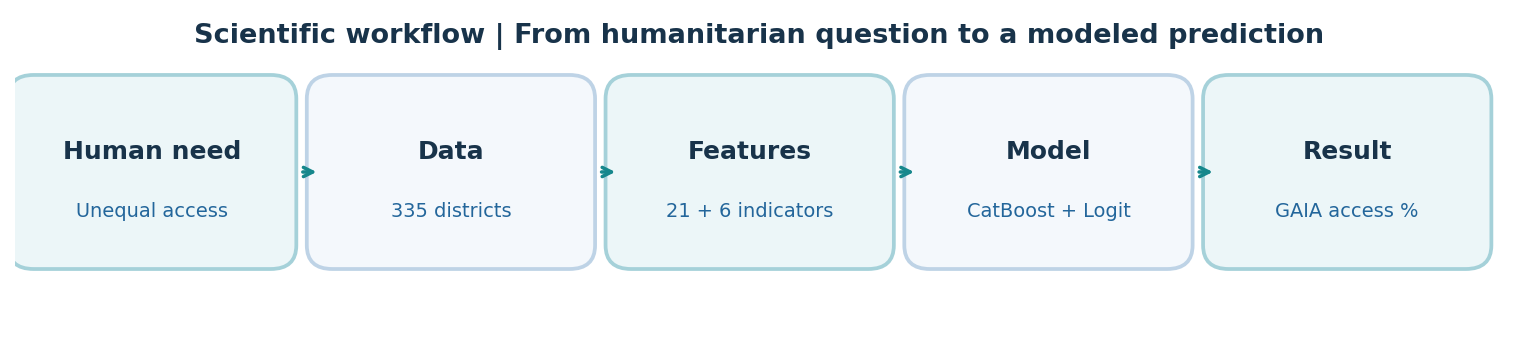

In [ ]:
# رسم توضيحي ثابت لمسار المشروع؛ لا يتدرّب هنا أي نموذج.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(12.8, 2.8))
ax.set_xlim(0, 12.8); ax.set_ylim(0, 3); ax.axis('off')
steps = [('Human need', 'Unequal access'), ('Data', '335 districts'),
         ('Features', '21 + 6 indicators'), ('Model', 'CatBoost + Logit'),
         ('Result', 'GAIA access %')]
for j, (heading, detail) in enumerate(steps):
    x = .10 + j * 2.57
    box = FancyBboxPatch((x, .8), 2.16, 1.48, boxstyle='round,pad=.16,rounding_size=.22',
                         fc='#ECF6F8' if j % 2 == 0 else '#F4F8FC', ec='#A5D1D9', lw=1.8)
    ax.add_patch(box)
    ax.text(x + 1.08, 1.73, heading, ha='center', va='center', fontsize=12, weight='bold', color='#18334A')
    ax.text(x + 1.08, 1.18, detail, ha='center', va='center', fontsize=9.3, color='#23669B')
    if j < len(steps) - 1:
        ax.annotate('', xy=(x + 2.53, 1.54), xytext=(x + 2.34, 1.54),
                    arrowprops=dict(arrowstyle='->', lw=1.7, color='#16878C'))
ax.set_title('Scientific workflow | From humanitarian question to a modeled prediction', fontsize=13, weight='bold')
plt.show()

<div dir="rtl" style="text-align:right"><b>🗣️ تفسير الرسم:</b> بدأنا بالمشكلة الإنسانية، ثم جمعنا بيانات المديريات، واستخرجنا المؤشرات، فدرّبنا نموذجًا للتنبؤ، وفي النهاية قمنا بالتقييم. **لا تخلط بين التنبؤ وبين إثبات أثر بناء مستشفى.**</div>


<a id="stage-1"></a>
<div dir="rtl" style="font-family:Cairo,Tahoma,sans-serif;text-align:right;line-height:1.7">

### المرحلة 1 — تجهيز بيئة Python والمكتبات

**🎯 هدف المرحلة:** تجهيز الأدوات اللازمة للقراءة والهندسة والتدريب والتقييم.

**🎤 ما أقوله أمام اللجنة:** «بدأنا باستدعاء Pandas للتعامل مع الجداول، وNumPy للحسابات، وscikit-learn للتقسيم والمقاييس، وCatBoost لتدريب النموذج. ثبّتنا البذرة العشوائية وجعلنا التدريب على CPU.»

**❓ سؤال متوقع:** لماذا نثبت البذرة العشوائية؟

**✅ إجابتي المختصرة:** لتقليل اختلاف النتائج بين التشغيلات؛ لكن النتيجة قد تتأثر قليلًا بإصدار المكتبة أو البيئة.

</div>


In [ ]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# 📚 استيراد المكتبات، التحقق من CatBoost، وتحديد البذرة والخيوط.
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# المكتبات اللازمة للتدريب والتحليل؛ يمكن تشغيل الدفتر على CPU.
import sys, subprocess, importlib.util, os, json, time, hashlib, gzip, base64, io
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.special import logit, expit
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

# تثبيت CatBoost عند الحاجة فقط؛ لا نثبت أو نحدث الحزم المثبتة تلقائياً.
if importlib.util.find_spec('catboost') is None:
    print('CatBoost غير مثبتة؛ نحتاج اتصالاً بالإنترنت لتثبيتها. يمكن استبدال هذه الخطوة بتثبيت مسبق.')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'catboost==1.2.10'])
from catboost import CatBoostRegressor
import sklearn, catboost

# نضبط خيوط CatBoost من أجل إعادة إنتاج أكثر استقراراً.
SEED = 2030
THREADS = 4
print('✅ البيئة جاهزة: Python',sys.version.split()[0], '| scikit-learn',sklearn.__version__, '| CatBoost',catboost.__version__)
print('📖 معنى المخرجات: هذه إصدارات المكتبات التي سنستخدمها أثناء إعادة التدريب.')


<div dir="rtl" style="text-align:right;line-height:1.7">

| المكتبة / الدالة | عملها في هذا الدفتر | كيف أشرحها ببساطة؟ |
|---|---|---|
| `pandas` | قراءة CSV ودمج البيانات | «جدول بيانات أستطيع تصفيته وربطه» |
| `numpy` | حساب المؤشرات والمصفوفات | «عمليات رقمية سريعة» |
| `CatBoostRegressor` | بناء نموذج انحدار | «مجموعة أشجار تتعلم العلاقات» |
| `GroupKFold` | فصل المحافظات | «نختبر على مناطق لم تدخل التدريب» |
| `SimpleImputer` | معالجة نقص القيم | «نتعلم بديل القيم الناقصة من التدريب فقط» |
| `logit` / `expit` | تحويل النسبة وإعادتها | «نحافظ على طبيعة الهدف المحصور بين 0 و100» |
| `MAE`, `RMSE`, `R²` | قياس الأداء | «كم يخطئ النموذج؟ وكيف تتوزع الأخطاء؟» |

</div>


<a id="stage-2"></a>
<div dir="rtl" style="font-family:Cairo,Tahoma,sans-serif;text-align:right;line-height:1.7">

### المرحلة 2 — تحميل البيانات والتحقق من سلامتها

**🎯 هدف المرحلة:** فهم الملفات الثلاثة، وما الهدف الذي نتعلم توقعه.

**🎤 ما أقوله أمام اللجنة:** «لدينا 335 صفًا؛ كل صف يمثل مديرية، لا شخصًا. نتحقق من بصمة كل ملف حتى لا نخلط بين نسخة التجربة وبيانات أخرى.»

**❓ سؤال متوقع:** لماذا نستخدم SHA-256؟

**✅ إجابتي المختصرة:** لمقارنة سلامة المحتوى الرقمي مع نسخة معتمدة؛ لا تعني البصمة أن البيانات صحيحة علميًا بمفردها.

</div>


<div dir="rtl" style="text-align:right;line-height:1.7">

| الملف المضمن | الوظيفة | هل يدخل مباشرة في التدريب؟ |
|---|---|---|
| `01_Yemen_ADM2_335_27_Features_Target_Folds.csv` | الميزات الـ27 + الهدف + الطيات | الميزات فقط؛ الهدف للتدريب والتقييم |
| `02_Source_ADM2_Raw_For_Engineering.csv` | المتغيرات الخام وإعادة اشتقاق الميزات | نستخدم أعمدة مدخلات محددة، لا الأعمدة الناتجة عن الوصول |
| `03_Geospatial_Six_Approved_Features.csv` | 6 مؤشرات OSM جاهزة | نعم، بعد المطابقة بمعرّف المديرية |

**تسميات مهمة:** `ADM2_PCODE` رمز المديرية؛ `ADM1_PCODE` رمز المحافظة؛ `hospital_access_pct` الهدف؛ `outer_fold` رقم مجموعة التقييم. **لا ندخل الرموز أو الهدف ضمن الـ27 مدخلًا.**

</div>


In [ ]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# 📦 ثلاثة ملفات CSV مضغوطة مضمنة داخل الدفتر؛ لا تُعدل النصوص المشفّرة أو بصماتها.
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# النسخة المضمنة مضغوطة ومحمية ببصمات SHA-256؛ لا تدخل نتائج OOF المرجعية في التدريب.
EMBEDDED_DATA = {
    '01_Yemen_ADM2_335_27_Features_Target_Folds.csv': (
        '...'
    ),
    '02_Source_ADM2_Raw_For_Engineering.csv': (
        '...'
    ),
    '03_Geospatial_Six_Approved_Features.csv': (
        '...'
    ),
}
EMBEDDED_SHA256 = {'01_Yemen_ADM2_335_27_Features_Target_Folds.csv': 'eeb86acb1e919a0a462b7e61e60559d78d2dadf260c805d3598bf3e2bf9bb845', '02_Source_ADM2_Raw_For_Engineering.csv': 'd0c4833963a742e1ceb327cd03670b21b28e9575451e8a77cd623e6e65486b83', '03_Geospatial_Six_Approved_Features.csv': 'b3b6ef920ed94cb035d1b1750cdd8db484ef8755ae8a44cdd9d64cac845dfabc'}


In [ ]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# 🔍 اختيار البيانات، فك ضغطها عند الحاجة، التحقق من SHA-256 ثم فتح الجداول.
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# نختار الملفات المباشرة من Kaggle إن وُجدت؛ وإلا ننشئها من النسخة المضمنة.
DATA_FILES = sorted(EMBEDDED_DATA)
DATA_ROOT = None
LOOK_IN = [Path.cwd(), Path('/kaggle/working'), Path('/kaggle/input'), Path('/mnt/data')]
for parent in LOOK_IN:
    if not parent.exists():
        continue
    paths = sorted(parent.glob('**/01_Yemen_ADM2_335_27_Features_Target_Folds.csv')) if str(parent) in ('/kaggle/input',) else list(parent.glob('data/01_Yemen_ADM2_335_27_Features_Target_Folds.csv'))
    for path in paths:
        if all((path.parent / f).is_file() for f in DATA_FILES):
            DATA_ROOT = path.parent
            break
    if DATA_ROOT is not None: break

if DATA_ROOT is None:
    DATA_ROOT = Path('/kaggle/working/yemen_health_demo_data') if Path('/kaggle/working').exists() else Path.cwd()/'yemen_health_demo_data'
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    for name, chunks in EMBEDDED_DATA.items():
        (DATA_ROOT/name).write_bytes(gzip.decompress(base64.b64decode(''.join(chunks))))
    print('✅ تم تجهيز نسخة البيانات المضمنة داخل الدفتر.')
else:
    print('✅ تم العثور على البيانات ضمن المسار:',DATA_ROOT)

# نقارن المحتوى ببصمات نسختنا المعتمدة قبل حساب أي نتيجة.
for name, expected_hash in EMBEDDED_SHA256.items():
    actual_hash = hashlib.sha256((DATA_ROOT/name).read_bytes()).hexdigest()
    assert actual_hash == expected_hash, f'تحذير: تغيّرت بيانات الملف: {name}'
print('✅ اجتازت ملفات البيانات الثلاثة فحص SHA-256.')

frozen = pd.read_csv(DATA_ROOT/'01_Yemen_ADM2_335_27_Features_Target_Folds.csv',
                     dtype={'ADM2_PCODE':'string','ADM1_PCODE':'string'})
raw_data = pd.read_csv(DATA_ROOT/'02_Source_ADM2_Raw_For_Engineering.csv',
                       dtype={'ADM2_PCODE':'string','ADM1_PCODE':'string'})
geo_data = pd.read_csv(DATA_ROOT/'03_Geospatial_Six_Approved_Features.csv',
                       dtype={'ADM2_PCODE':'string','ADM1_PCODE':'string'})
print(f'عدد المديريات: {len(frozen)}, عدد المحافظات: {frozen.ADM1_PCODE.nunique()}')
display(frozen[['ADM2_PCODE','ADM1_PCODE','hospital_access_pct','outer_fold']].head(7))
print('📖 تفسير المخرجات: كل صف يمثل مديرية؛ الهدف نسبة الوصول المقدّرة، وouter_fold رقم طية التقييم.')


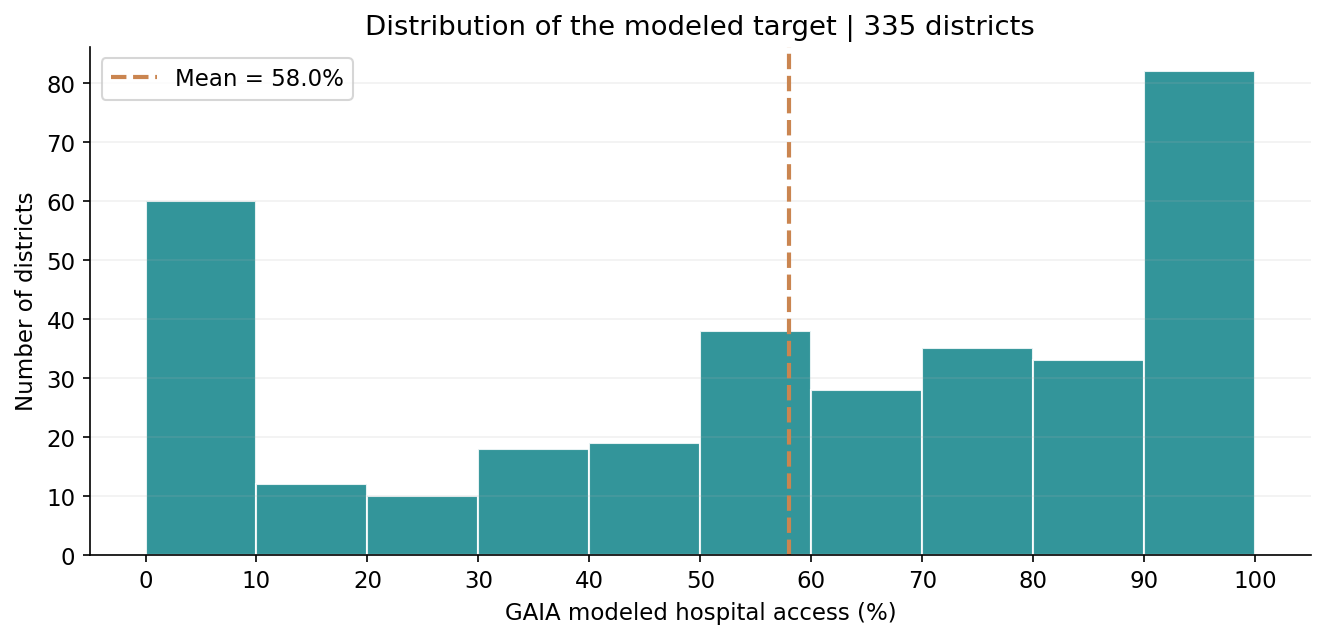

In [ ]:
# رسم البيانات الفعلية: توزيع هدف GAIA عبر المديريات (لا توجد تنبؤات في هذا الرسم).
import numpy as np
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10.5,4.4))
ax.hist(frozen['hospital_access_pct'], bins=np.arange(0, 105, 10),
        color='#16878C', edgecolor='white', alpha=.88)
ax.axvline(frozen['hospital_access_pct'].mean(), color='#CA8550', ls='--', lw=2,
           label=f"Mean = {frozen['hospital_access_pct'].mean():.1f}%")
ax.set(title='Distribution of the modeled target | 335 districts',
       xlabel='GAIA modeled hospital access (%)', ylabel='Number of districts')
ax.set_xticks(np.arange(0,101,10)); ax.grid(axis='y', alpha=.17); ax.legend()
plt.show()

<div dir="rtl" style="text-align:right;line-height:1.8">

**🎤 ماذا أقول عن الرسم؟** «قيم الهدف موزعة بين 0% و100%، والمتوسط غير الموزون للمديريات في هذه الملفات هو **57.97%**. هذا **ليس** متوسط السكان الوطني؛ فهو يعامل المديريات بأوزان متساوية.»

**سؤال متوقع:** هل نسبة 58% تعني أن 58% من سكان اليمن يمكنهم الوصول؟  
**الإجابة:** لا. هي متوسط حسابي غير موزون **لقيم المديريات في ملف الدراسة**، وليست نسبة وطنية موزونة بالسكان.

</div>


<a id="stage-3"></a>
<div dir="rtl" style="font-family:Cairo,Tahoma,sans-serif;text-align:right;line-height:1.7">

### المرحلة 3 — هندسة الميزات ومنع التسرب

**🎯 هدف المرحلة:** شرح كيف نصنع مؤشرات تعكس الواقع، دون إدخال النتيجة التي نحاول توقعها.

**🎤 ما أقوله أمام اللجنة:** «بدل الاكتفاء بعدد المستشفيات، حولناه إلى مؤشرات مثل عدد المستشفيات لكل 100 ألف نسمة وكثافة السكان وتفاعل الطرق مع المرافق. ثم أضفنا 6 ميزات مكانية من OSM ليصبح المجموع 27.»

**❓ سؤال متوقع:** ما هو Data Leakage؟

**✅ إجابتي المختصرة:** هو إدخال معلومات من الإجابة أو بيانات الاختبار إلى خطوات تدريب يفترض أنها لا تراها، فيبدو الأداء أفضل من الحقيقة.

</div>


<div dir="rtl" style="text-align:right;line-height:1.75">

### 🧩 مجموعات الميزات باختصار

| المجموعة | أمثلة من الأعمدة | لماذا تساعد؟ |
|---|---|---|
| السكان والجغرافيا | `total_pop`, `area_km2`, `pop_density` | توضح حجم السكان وتوزعهم |
| المنشآت الصحية | `hospitals_count`, `primary_healthcare_count`, `hospitals_per_100k` | تقيس عدد وتوفر الخدمات الصحية |
| الريف والطرق | `rural_pop_perc`, `RAI_total_pop`, `road_x_hospitals_density` | تربط التفاوت الريفي بمؤشر الطرق |
| الميزات المشتقة | `hospital_present`, `log_total_pop`, `facility_density_x_road` | تكشف أنماطًا وتفاعلات إضافية |
| OSM الجغرافية (6) | `osm_motor_road_km_per_km2`, `osm_mapped_hospitals_25km_centroid` | تضيف سياق شبكة الطرق والمرافق القريبة |

**صيغة سهلة أحفظها:**  
`hospitals_per_100k = 100000 × hospitals_count / total_pop`

**تحذير:** `RAI_total_pop` مؤشر متعلق بإمكانية الوصول عبر الطرق الريفية، **وليس** نسبة الوصول إلى المستشفيات نفسها.

</div>


In [ ]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# 🛠️ قوائم الميزات، إعادة اشتقاق 21 مؤشرًا، دمج OSM، واستبعاد الهدف من المدخلات.
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# قوائم الميزات: 21 ميزة مشتقة + 6 ميزات مكانية؛ قائمة صريحة تمنع تسرب الهدف.
BASE_FEATURES = [
 'total_pop','hospitals_count','primary_healthcare_count','rural_pop_perc','area_km2',
 'pop_density','hospitals_per_100k','primary_healthcare_per_100k','log_total_pop',
 'RAI_total_pop','served_rural_pct','unserved_rural_pct',
 'road_x_hospitals_density','road_x_healthcare_density','hospital_present',
 'log_pop_density','healthcare_facilities_per_km2','hospitals_per_km2',
 'facility_density_x_rural','facility_density_x_road','hospital_presence_x_rural_x_road'
]
GEO_FEATURES = [
 'osm_motor_road_km_per_km2','osm_motor_road_km_per_10k_pop',
 'osm_major_road_share','osm_track_road_share',
 'osm_mapped_hospitals_25km_centroid','osm_mapped_hospitals_50km_centroid'
]
FEATURES = BASE_FEATURES + GEO_FEATURES
FORBIDDEN = {'ADM2_PCODE','ADM1_PCODE','hospital_access_pct','outer_fold','access_pop_hospitals_1h'}
assert len(FEATURES)==27 and not FORBIDDEN.intersection(FEATURES)

def engineer_approved_features(source):
    """تحويل الخصائص الخام إلى مؤشرات قابلة للتعلم؛ الهدف والرموز خارج الحسابات."""
    f = source.copy()
    for c in ['total_pop','hospitals_count','primary_healthcare_count',
              'rural_pop_perc','RAI_total_pop','area_km2']:
        f[c] = pd.to_numeric(f[c],errors='coerce')
    pop = f['total_pop'].where(f['total_pop']>0)
    area = f['area_km2'].where(f['area_km2']>0)
    hospitals = f['hospitals_count']
    phc = f['primary_healthcare_count']
    rural = f['rural_pop_perc']
    rai = f['RAI_total_pop'].where(f['RAI_total_pop'].between(0,100))
    f['log_total_pop'] = np.log1p(pop)
    f['pop_density'] = pop/area
    f['hospitals_per_100k'] = 1e5*hospitals/pop
    f['primary_healthcare_per_100k'] = 1e5*phc/pop
    f['served_rural_pct'] = rural*rai/100
    f['unserved_rural_pct'] = rural*(1-rai/100)
    f['road_x_hospitals_density'] = f['hospitals_per_100k']*rai/100
    f['road_x_healthcare_density'] = f['primary_healthcare_per_100k']*rai/100
    f['hospital_present'] = (hospitals>0).astype(float)
    f['log_pop_density'] = np.log1p(f['pop_density'].where(f['pop_density']>=0))
    f['healthcare_facilities_per_km2'] = (hospitals+phc)/area
    f['hospitals_per_km2'] = hospitals/area
    log_facility_density = np.log1p(f['healthcare_facilities_per_km2'].where(lambda s:s>=0))
    f['facility_density_x_rural'] = log_facility_density*(rural/100)
    f['facility_density_x_road'] = log_facility_density*(rai/100)
    f['hospital_presence_x_rural_x_road'] = f['hospital_present']*(rural/100)*(rai/100)
    for c in BASE_FEATURES:
        f[c] = pd.to_numeric(f[c],errors='coerce').replace([np.inf,-np.inf],np.nan)
    return f

joined = raw_data.merge(geo_data[['ADM2_PCODE','ADM1_PCODE']+GEO_FEATURES],
                        on=['ADM2_PCODE','ADM1_PCODE'],validate='one_to_one',sort=False)
features_rebuilt = engineer_approved_features(joined)
reconstructed = features_rebuilt[['ADM2_PCODE','ADM1_PCODE']+BASE_FEATURES+GEO_FEATURES]
compared = frozen[['ADM2_PCODE','ADM1_PCODE']+FEATURES].merge(
    reconstructed,on=['ADM2_PCODE','ADM1_PCODE'],suffixes=('_frozen','_rebuilt'),validate='one_to_one')
max_feature_diff = max(float(np.max(np.abs(compared[f+'_frozen']-compared[f+'_rebuilt']))) for f in FEATURES)
assert max_feature_diff < 1e-7, f'فشل تطابق الميزات: {max_feature_diff}'
assert len(frozen)==335 and frozen.ADM2_PCODE.is_unique and frozen.ADM1_PCODE.nunique()==22
assert np.isfinite(frozen[FEATURES].to_numpy(float)).all()
assert frozen.hospital_access_pct.between(0,100).all()
assert sorted(frozen.outer_fold.unique().tolist()) == [1,2,3,4,5]
for fold in sorted(frozen.outer_fold.unique()):
    gov_train=set(frozen.loc[frozen.outer_fold!=fold,'ADM1_PCODE'])
    gov_test=set(frozen.loc[frozen.outer_fold==fold,'ADM1_PCODE'])
    assert not gov_train.intersection(gov_test), 'تسرب المحافظات عبر الطيات!'
print(f'✅ تم إعادة اشتقاق 27 ميزة بنجاح؛ أقصى فرق عددي = {max_feature_diff:.2e}')
print('✅ البيانات سليمة: 335 مديرية، 22 محافظة، 5 طيات لا تتداخل فيها المحافظات.')
print('📖 تفسير النتيجة: تطابق الميزات يعني أننا نعيد بناء مدخلات EXP_0012، وليس أننا استخدمنا الهدف في هندسة الميزات.')


<a id="stage-4"></a>
<div dir="rtl" style="font-family:Cairo,Tahoma,sans-serif;text-align:right;line-height:1.7">

### المرحلة 4 — تقسيم المحافظات إلى مجموعات تدريب واختبار

**🎯 هدف المرحلة:** تفسير لماذا اختبرنا النموذج على محافظات كاملة بدل فصل المديريات عشوائيًا.

**🎤 ما أقوله أمام اللجنة:** «المديريات الواقعة في المحافظة نفسها قد تتشابه؛ لذلك اعتمدنا 5 طيات خارجية. في كل جولة ندرّب على أربع مجموعات محافظات، ونتنبأ للمجموعة الخامسة. اختيار وزن المزج يتم بـ3 طيات داخل التدريب فقط.»

**❓ سؤال متوقع:** لماذا ليس Train/Test Split عشوائيًا؟

**✅ إجابتي المختصرة:** لأن وجود مديريات من المحافظة نفسها في الطرفين قد يعطي تقديرًا أكثر تفاؤلًا مما نريده عند تقييم التعميم المكاني.

</div>


In [ ]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# 🧭 عرض التقسيم المجمد للمحافظات ثم إعداد X وy ودالتي النموذج والمقاييس.
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# نظهر المحافظات المستبعدة من التدريب في كل جولة.
fold_summary = []
for fold in range(1,6):
    test_rows = frozen[frozen.outer_fold==fold]
    fold_summary.append({'الطية':fold,'عدد المديريات':len(test_rows),
                         'المحافظات المحجوبة':', '.join(sorted(test_rows.ADM1_PCODE.unique()))})
display(pd.DataFrame(fold_summary))
X = frozen[FEATURES].copy()
y = frozen['hospital_access_pct'].to_numpy(dtype=float)
groups = frozen['ADM1_PCODE'].astype(str).to_numpy()
outer_fold = frozen['outer_fold'].to_numpy(dtype=int)

def new_catboost():
    """النموذج نفسه المعتمد سابقاً دون ضبط جديد على الطيات الخارجية."""
    return CatBoostRegressor(loss_function='MAE',iterations=300,depth=4,
                             learning_rate=0.05,l2_leaf_reg=5.0,
                             random_seed=2030,verbose=False,thread_count=THREADS,
                             allow_writing_files=False)

def compute_metrics(y_true,pred):
    return {'MAE_pp':float(mean_absolute_error(y_true,pred)),
            'RMSE_pp':float(np.sqrt(mean_squared_error(y_true,pred))),
            'R2':float(r2_score(y_true,pred))}
print('📖 الجدول يبين المحافظات المحجوبة في كل طية؛ لا تظهر محافظة في تدريب الطية واختبارها معًا.')


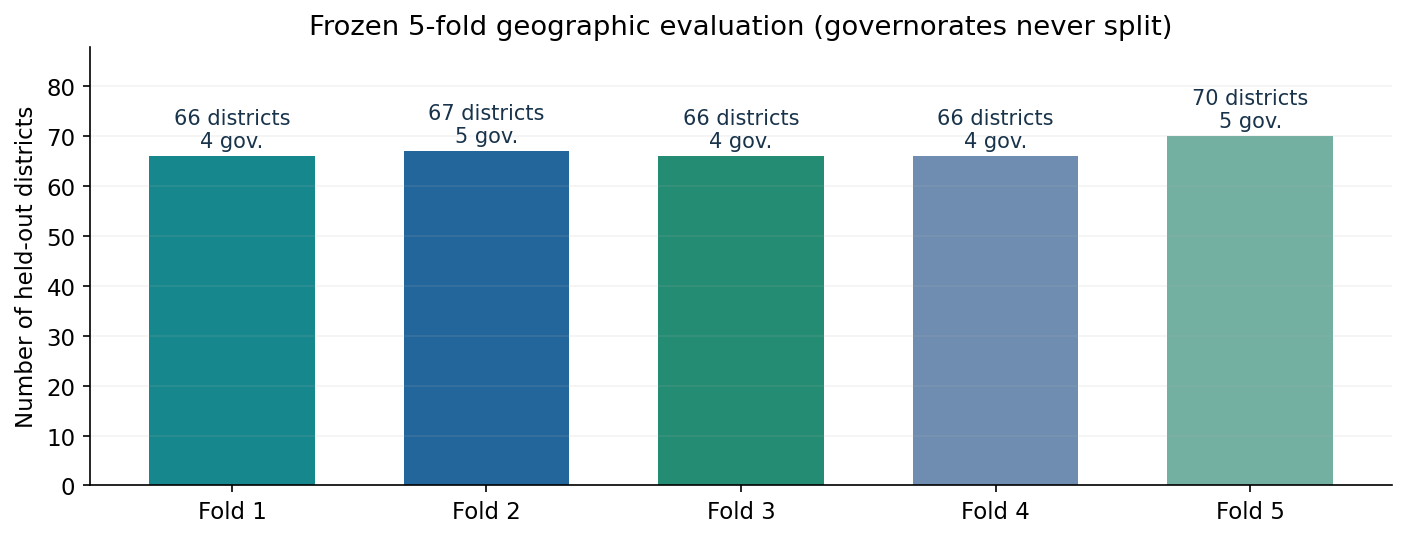

In [ ]:
# رسم عدد مديريات الاختبار في الطيات الخمس المجمدة من البيانات الأصلية.
fold_counts = frozen.groupby('outer_fold').size().reindex([1,2,3,4,5])
gov_counts = frozen.groupby('outer_fold')['ADM1_PCODE'].nunique().reindex([1,2,3,4,5])
fig, ax = plt.subplots(figsize=(11.2,3.8))
bars = ax.bar([f'Fold {i}' for i in fold_counts.index], fold_counts.values,
              color=['#16878C','#23669B','#248C72','#6F8DB1','#73B0A2'],width=.65)
for bar, n_g in zip(bars, gov_counts):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
            f'{int(bar.get_height())} districts\n{n_g} gov.',ha='center',va='bottom',fontsize=10)
ax.set(ylim=(0,88),ylabel='Number of held-out districts',
       title='Frozen 5-fold geographic evaluation (governorates never split)')
ax.grid(axis='y',alpha=.15);plt.show()

<div dir="rtl" style="text-align:right;line-height:1.8">

**🎤 تفسير الرسم:** «لدينا خمس مجموعات اختبار، كل واحدة تحتوي محافظات كاملة. الفرق بين أعداد المديريات طبيعي لأن المحافظات ليست متساوية الحجم. الهدف أن نقيس التنبؤ خارج المحافظات الداخلة في تدريب تلك الجولة.»

**تذكّر الفرق:** `5 outer folds` لاختبار النتائج؛ `3 inner folds` لاختيار وزن المزج **دون رؤية اختبار الجولة الخارجية**.

</div>


<a id="stage-5"></a>
<div dir="rtl" style="font-family:Cairo,Tahoma,sans-serif;text-align:right;line-height:1.7">

### المرحلة 5 — تدريب CatBoost الأساسي والحصول على OOF

**🎯 هدف المرحلة:** فهم فكرة نموذج الأشجار والتنبؤ خارج بيانات تدريب كل طية.

**🎤 ما أقوله أمام اللجنة:** «يدرب CatBoost مجموعة أشجار قرار صغيرة ويتعلم أنماطًا غير خطية. نحسب تنبؤًا لكل مديرية من نموذج لم يتدرب على محافظتها، ونسمّي هذا Out-Of-Fold أو OOF.»

**❓ سؤال متوقع:** هل النموذج حفظ نسبة كل مديرية؟

**✅ إجابتي المختصرة:** لا. يتعلم قواعد من المؤشرات. وOOF دليل على أن التنبؤ في الاختبار صدر من نموذج لم يتدرب على تلك الصفوف.

</div>


<div dir="rtl" style="text-align:right;line-height:1.75">

| معامل CatBoost | القيمة في الدفتر | التفسير السريع |
|---|---:|---|
| `iterations` | 300 | عدد الأشجار / جولات التعزيز |
| `depth` | 4 | عمق كل شجرة |
| `learning_rate` | 0.05 | حجم التحديث من كل شجرة |
| `l2_leaf_reg` | 5.0 | تنظيم لمقاومة المبالغة في التعلّم |
| `loss_function` | MAE | خطأ التدريب المستهدف |
| `random_seed` | 2030 | يساعد على تكرار التجربة |

**ما الذي يعمله `SimpleImputer`؟** يتعلم وسيط كل عمود من صفوف التدريب **فقط** ثم يستخدمه مع بيانات الاختبار، منعًا للتسرب.

</div>


In [ ]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# 🌳 خمس جولات تدريب CatBoost: تدريب فقط على المحافظات المسموحة ثم حفظ تنبؤات OOF.
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
start_time = time.perf_counter()
baseline_oof = np.full(len(y),np.nan)
for fold in range(1,6):
    tr = np.flatnonzero(outer_fold != fold)
    te = np.flatnonzero(outer_fold == fold)
    assert not set(groups[tr]).intersection(groups[te])
    imputer = SimpleImputer(strategy='median')
    x_tr = imputer.fit_transform(X.iloc[tr])  # نتعلم التعويض من التدريب فقط.
    x_te = imputer.transform(X.iloc[te])      # ثم نطبّق التعويض على الاختبار.
    mdl = new_catboost()
    mdl.fit(x_tr,y[tr])
    baseline_oof[te] = np.clip(mdl.predict(x_te),0,100)
    print(f'الطية {fold}/5 | مديريات الاختبار: {len(te):3} | MAE: {mean_absolute_error(y[te],baseline_oof[te]):.4f} نقطة')
assert np.isfinite(baseline_oof).all()
BASE_METRICS = compute_metrics(y,baseline_oof)
print('\n✅ تم تجهيز تنبؤ المكوّن الأساسي داخل EXP_0012:',BASE_METRICS)
print('زمن هذه المرحلة: %.2f ثانية' % (time.perf_counter()-start_time))
print('📖 هذه الأرقام تصف المكوّن الأساسي فقط. نتيجة التجربة النهائية ستظهر بعد مزجه مع مكوّن Logit.')


<a id="stage-6"></a>
<div dir="rtl" style="font-family:Cairo,Tahoma,sans-serif;text-align:right;line-height:1.7">

### المرحلة 6 — مكوّن Logit ثم مزج النموذجين

**🎯 هدف المرحلة:** شرح جوهر تحسين EXP_0012 وكيف نحسب وزن المزج α دون استخدام اختبار الطية الخارجية.

**🎤 ما أقوله أمام اللجنة:** «لدينا نفس بيانات الإدخال، لكن مكوّنًا يتعلم النسبة مباشرة، وآخر يتعلم نسبة محوّلة بـLogit ثم نعيدها إلى المجال المئوي بـSigmoid. نجرب أوزان المزج داخل المحافظات التدريبية ونحتفظ بالوزن الأفضل في تلك الجولة.»

**❓ سؤال متوقع:** لماذا نحتاج نموذجين؟ وهل هذا Ensemble؟

**✅ إجابتي المختصرة:** نعم، هذه تجربة مزج تنبؤين من CatBoost لهما هدفان بصيغتين مختلفتين، ضمن EXP_0012 واحدة.

</div>


<div dir="rtl" style="text-align:right;line-height:1.8">

### 📐 المعادلة التي يجب أن أفهمها

**أولًا:** نحوّل نسبة الهدف إلى قيمة بين صفر وواحد ونتجنب `log(0)`:

\[
p=\operatorname{clip}\left(\frac{y}{100},\varepsilon,1-\varepsilon\right),\quad \varepsilon=0.0015
\]

**ثانيًا:** تحويل `Logit` ثم عكسه عند التنبؤ:

\[
z=\log\left(\frac{p}{1-p}\right),\qquad
\widehat y_{\mathrm{logit}}=100\,\sigma(\widehat z)
\]

**ثالثًا:** مزج النتيجتين:

\[
\widehat y_{\mathrm{EXP12}}=(1-\alpha)\,\widehat y_{\mathrm{base}}+\alpha\,\widehat y_{\mathrm{logit}}
\]

**تفسير α:** إذا كان `α = 0` استخدمنا المكوّن الأساسي فقط، وإذا `α = 1` استخدمنا Logit فقط، وما بينهما مزج. **لا تخلط بين وزن كل طية خارجية وبين وزن النموذج الكامل النهائي.**

**تحفظ علمي:** قيمة `ε` وبعض الخيارات تم تطويرها في تجارب سابقة باستخدام هذه البيانات، لذا الأداء استكشافي وليس اختبارًا خارجيًا مستقلًا محايدًا تمامًا.

</div>


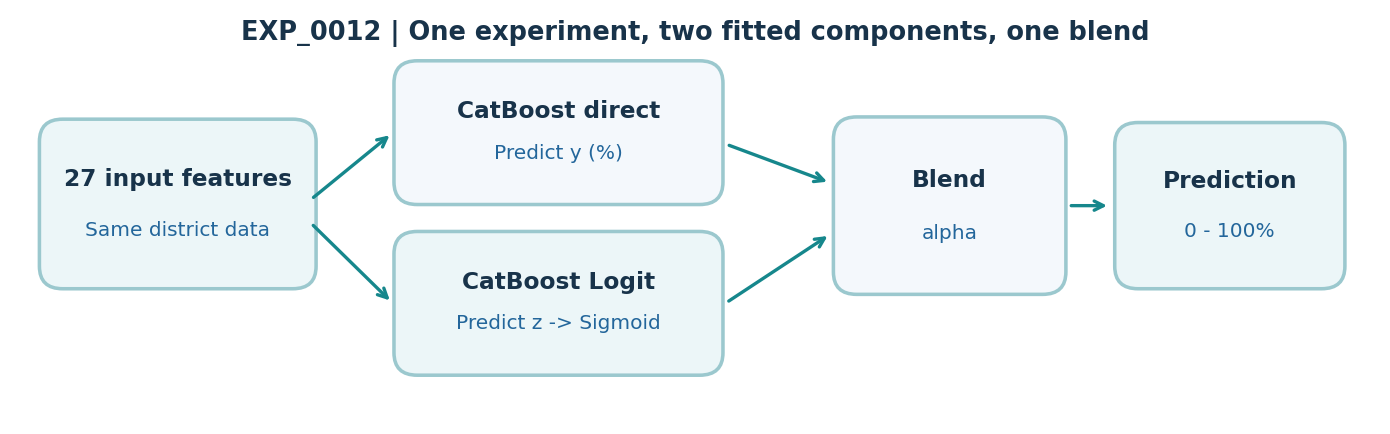

In [ ]:
# رسم مفاهيمي لعملية المزج EXP_0012، دون تنفيذ التدريب.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(11.7,3.5));ax.set_xlim(0,11.7);ax.set_ylim(0,3.6);ax.axis('off')
items = [(.35,1.30,2.1,1.23,'27 input features','Same district data'),
         (3.40,2.05,2.55,1.0,'CatBoost direct','Predict y (%)'),
         (3.40,.53,2.55,1.0,'CatBoost Logit','Predict z -> Sigmoid'),
         (7.18,1.25,1.72,1.3,'Blend','alpha'),(9.60,1.30,1.7,1.2,'Prediction','0 - 100%')]
for j,(x,y,w,h,title,subtitle) in enumerate(items):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=.14,rounding_size=.20',
                                fc='#ECF6F8' if j%2==0 else '#F4F8FC',ec='#9BC8CE',linewidth=1.7))
    ax.text(x+w/2,y+h*.63,title,ha='center',fontsize=11.2,weight='bold',color='#18334A')
    ax.text(x+w/2,y+h*.27,subtitle,ha='center',fontsize=9.7,color='#23669B')
for x1,y1,x2,y2 in [(2.54,1.95,3.25,2.55),(2.54,1.75,3.25,1.03),
                     (6.11,2.45,7.02,2.10),(6.11,1.03,7.02,1.65),(9.05,1.90,9.43,1.90)]:
    ax.annotate('',xy=(x2,y2),xytext=(x1,y1),arrowprops=dict(arrowstyle='->',lw=1.6,color='#16878C'))
ax.set_title('EXP_0012 | One experiment, two fitted components, one blend',fontsize=12.3,weight='bold')
plt.show()

In [ ]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# 🧠 3 طيات داخل كل تدريب خارجي لاختيار alpha، ثم تدريب Logit ودمج OOF دون التسرب للاختبار.
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# EXP_0012: خمس طيات خارجية؛ لكل طية ثلاث طيات داخلية لاختيار وزن المزج دون الاطلاع على الهدف الخارجي.
EPS = 0.0015
ALPHA_GRID = [0.0,0.10,0.20,0.25,0.35,0.50,0.65,0.75,1.0]
logit_oof = np.full(len(y),np.nan)
blend_oof = np.full(len(y),np.nan)
alpha_per_row = np.full(len(y),np.nan)
fold_details = []
start_time = time.perf_counter()
for fold in range(1,6):
    tr=np.flatnonzero(outer_fold!=fold)
    te=np.flatnonzero(outer_fold==fold)
    inner=GroupKFold(n_splits=3)
    inner_base=np.full(len(tr),np.nan)
    inner_logit=np.full(len(tr),np.nan)
    # التدريب الداخلي: لا نستخدم أي صف من المحافظات الخارجية المحجوبة.
    for itr, iva in inner.split(X.iloc[tr],y[tr],groups[tr]):
        fit_idx=tr[itr]
        val_idx=tr[iva]
        assert not set(groups[fit_idx]).intersection(groups[val_idx])
        imputer=SimpleImputer(strategy='median')
        xf=imputer.fit_transform(X.iloc[fit_idx]); xv=imputer.transform(X.iloc[val_idx])
        base_model=new_catboost(); base_model.fit(xf,y[fit_idx])
        inner_base[iva]=np.clip(base_model.predict(xv),0,100)
        logit_model=new_catboost()
        transformed_target=logit(np.clip(y[fit_idx]/100.0,EPS,1-EPS))
        logit_model.fit(xf,transformed_target)
        inner_logit[iva]=np.clip(100*expit(logit_model.predict(xv)),0,100)
    assert np.isfinite(inner_base).all() and np.isfinite(inner_logit).all()
    # اختيار وزن المزج: نفحص الأهداف الداخلية التدريبية فقط.
    scores={a:mean_absolute_error(y[tr],(1-a)*inner_base+a*inner_logit) for a in ALPHA_GRID}
    alpha=min(scores,key=scores.get)
    # إعادة التدريب على جميع المديريات التدريبية للطية الخارجية.
    imputer=SimpleImputer(strategy='median')
    xf=imputer.fit_transform(X.iloc[tr]); xv=imputer.transform(X.iloc[te])
    trained_logit=new_catboost()
    trained_logit.fit(xf,logit(np.clip(y[tr]/100.0,EPS,1-EPS)))
    logit_oof[te]=np.clip(100*expit(trained_logit.predict(xv)),0,100)
    # المرجع baseline_oof[te] تم إنتاجه من تدريب تلك الطية نفسها في المرحلة السابقة.
    blend_oof[te]=np.clip((1-alpha)*baseline_oof[te]+alpha*logit_oof[te],0,100)
    alpha_per_row[te]=alpha
    fold_details.append({'الطية':fold,'وزن Logit المختار':alpha,
                         'MAE المرجع':mean_absolute_error(y[te],baseline_oof[te]),
                         'MAE التحسين':mean_absolute_error(y[te],blend_oof[te])})
    print(f'الطية {fold}/5 | α={alpha:.2f} | MAE المرجع={fold_details[-1]["MAE المرجع"]:.4f} | MAE التحسين={fold_details[-1]["MAE التحسين"]:.4f}')
assert np.isfinite(logit_oof).all() and np.isfinite(blend_oof).all()
ENHANCED_METRICS=compute_metrics(y,blend_oof)
print('\n✅ هذه المقاييس مُحتسبة من التدريب الحقيقي:',ENHANCED_METRICS)
print('زمن مرحلة التحسين: %.2f ثانية' % (time.perf_counter()-start_time))
display(pd.DataFrame(fold_details))
print('📖 معنى السطور: α وزن مكوّن Logit؛ وMAE التحسين هو خطأ EXP_0012 الفعلي على محافظات الاختبار المحجوبة.')


<a id="stage-7"></a>
<div dir="rtl" style="font-family:Cairo,Tahoma,sans-serif;text-align:right;line-height:1.7">

### المرحلة 7 — قراءة نتائج التقييم دون مبالغة

**🎯 هدف المرحلة:** شرح المقاييس ومعنى النقاط المئوية والفروق بين النتائج السابقة والتشغيل الحالي.

**🎤 ما أقوله أمام اللجنة:** «نقيس متوسط الخطأ المطلق MAE، وخطأ RMSE الذي يعاقب الانحرافات الكبيرة أكثر، ومعامل التحديد R². أهم شيء: R² ليس Accuracy. سأعرض ما نتج من التشغيل الحالي بجانب القيم المسجلة سابقًا.»

**❓ سؤال متوقع:** هل R² = 0.7258 يعني دقة 72.58%؟

**✅ إجابتي المختصرة:** لا. هذا معامل تحديد؛ والمقياس الأسهل لتفسير فرق النسب هو MAE بوحدة النقاط المئوية.

</div>


<div dir="rtl" style="text-align:right;line-height:1.75">

| المقياس | ماذا يقيس؟ | اتجاه الأفضل | قيمة EXP_0012 السابقة * |
|---|---|---|---:|
| MAE | متوسط المسافة المطلقة بين التوقع والهدف | الأقل | **12.8882 نقطة مئوية** |
| RMSE | يعاقب الأخطاء الكبيرة بشكل أوضح | الأقل | **18.1766 نقطة مئوية** |
| R² | مقارنة جودة التنبؤ بخط أساس متوسط الهدف | الأعلى | **0.72585** |

*هذه **قيم تاريخية مرجعية استكشافية** من الدفتر الأصلي؛ الأرقام التي تحسبها الخلية التالية عند التشغيل هي الحكم على إعادة الإنتاج في البيئة الحالية.*

**سيناريو توضيحي:** لو كانت قيمة GAIA لمديرية هي 70%، وتوقعنا 58%، فالخطأ المطلق لتلك المديرية **12 نقطة مئوية**. هذا مثال حسابي للتفسير، وليس سطرًا مختلقًا من النتائج.

</div>


In [ ]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# 📊 حساب MAE وRMSE وR² والأخطاء الكبيرة من OOF الفعلي؛ مقارنة منفصلة بالقيم التاريخية.
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# المقاييس محسوبة من تنبؤات الطيات الخارجية؛ لم نحصل عليها من ملف نتائج محفوظ.
EXPECTED_EXP12 = {'MAE_pp': 12.88823384, 'RMSE_pp': 18.17657202, 'R2': 0.7258466451}
results = pd.DataFrame([
    {'المصدر': 'نتيجة EXP_0012 من التشغيل الحالي', **ENHANCED_METRICS},
    {'المصدر': 'النتيجة السابقة المرجعية', **EXPECTED_EXP12},
])
display(results.round(6))

# مؤشرات الأخطاء الشديدة تبيّن كم مديرية يصعب توقع قيمتها بدقة.
absolute_error = np.abs(y - blend_oof)
print('🏥 عدد المديريات:', len(y), '| عدد المحافظات:', len(set(groups)))
print('📉 MAE = %.4f نقطة مئوية: متوسط مقدار الخطأ المطلق.' % ENHANCED_METRICS['MAE_pp'])
print('📉 RMSE = %.4f: مقياس حساس للأخطاء الكبيرة.' % ENHANCED_METRICS['RMSE_pp'])
print('📈 R² = %.5f: معامل تحديد، وليس دقة تصنيف.' % ENHANCED_METRICS['R2'])
print('⚠️ أخطاء ≥30 نقطة:', int((absolute_error >= 30).sum()),
      '| ≥40:', int((absolute_error >= 40).sum()),
      '| ≥50:', int((absolute_error >= 50).sum()))
print('🔍 فرق MAE عن النتيجة المرجعية = %+0.6f نقطة.' % (ENHANCED_METRICS['MAE_pp'] - EXPECTED_EXP12['MAE_pp']))
print('📖 هذه أرقام تقييم تجريبي OOF داخل المشروع؛ لا تثبت قياسًا ميدانيًا أو تعميمًا مستقلاً على محافظات جديدة.')


<a id="stage-8"></a>
<div dir="rtl" style="font-family:Cairo,Tahoma,sans-serif;text-align:right;line-height:1.7">

### المرحلة 8 — قراءة الرسوم والجداول وتحليل تفاوت المحافظات

**🎯 هدف المرحلة:** تحليل أين يصيب النموذج وأين يخطئ بدل الاعتماد على متوسط واحد.

**🎤 ما أقوله أمام اللجنة:** «أعرض علاقة الهدف بالتنبؤ: كلما اقتربت النقطة من القطر كانت أقرب للصواب. وأعرض توزيع الأخطاء لنرى المديريات التي يصعب توقعها، ثم أقارن MAE بين المحافظات.»

**❓ سؤال متوقع:** ماذا لو كانت بعض المحافظات أصعب من غيرها؟

**✅ إجابتي المختصرة:** هذه إشارة إلى تفاوت تعميم النموذج؛ نحتاج دراسة جودة المؤشرات وتنوع المحافظات، دون الجزم بسبب واحد من الرسم فقط.

</div>


In [ ]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# 📈 رسم الهدف مقابل التنبؤ، توزيع الخطأ المطلق، وجدول MAE بحسب المحافظة.
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# نعرض مقارنة الهدف النموذجي بالتنبؤات وتوزيع مقدار الخطأ.
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].scatter(y, blend_oof, s=18, alpha=.65, label='EXP_0012 OOF')
axs[0].plot([0,100],[0,100],linestyle='--',color='black',linewidth=1,label='Perfect prediction')
axs[0].set(xlabel='GAIA target (%)', ylabel='Predicted (%)', title='Target vs prediction')
axs[0].legend()
axs[1].hist(absolute_error, bins=18, edgecolor='white')
axs[1].set(xlabel='Absolute error (percentage points)', ylabel='District count', title='Absolute error distribution')
plt.tight_layout(); plt.show()

# حساب MAE بكل محافظة دون إخفاء التفاوت خلف المتوسط العام.
gov_table = (pd.DataFrame({'المحافظة': groups, 'الخطأ_المطلق': absolute_error})
             .groupby('المحافظة', as_index=False)
             .agg(عدد_المديريات=('الخطأ_المطلق','size'), MAE=('الخطأ_المطلق','mean'))
             .sort_values('MAE',ascending=False))
display(gov_table.round(3))
print('🌍 متوسط MAE عند وزن المحافظات بالتساوي = %.4f نقطة.' % gov_table['MAE'].mean())
print('📖 المحافظات الأعلى في الجدول هي الأصعب توقعًا في هذا التقييم؛ ينبغي مناقشة الأسباب المحتملة دون الجزم بسبب واحد.')


In [ ]:
# رسم إضافي يعتمد على نتائج هذه الجلسة فقط؛ لا يستخدم أي قيم تاريخية ثابتة.
# بعد تشغيل المرحلة السابقة يصبح gov_table متاحًا.
strongest = gov_table.head(12).sort_values('MAE', ascending=True)
fig, ax = plt.subplots(figsize=(10.5,5.1))
ax.barh(strongest['المحافظة'].astype(str), strongest['MAE'],color='#23669B')
ax.set(xlabel='MAE (percentage points)',ylabel='Governorate code',
       title='12 governorates with the highest OOF MAE in this run')
ax.grid(axis='x',alpha=.16)
plt.tight_layout();plt.show()
print('📖 تفسير الرسم: المحافظات الأعلى MAE هي الأصعب توقعًا في هذا التشغيل، لا يعني ذلك بالضرورة أنها الأقل خدمات صحية.')

<div dir="rtl" style="text-align:right;line-height:1.75">

**🗣️ جملة تربط الرسوم بالقصة:** «الرقم العام مفيد، لكنه قد يخفي فروقًا جغرافية. لذلك فحصنا التوقعات مديريةً ومديريةً، ثم جمعنا الأخطاء لكل محافظة. ارتفاع الخطأ في محافظة لا يعني تلقائيًا أن الوصول الصحي فيها أضعف، بل أن النموذج أخطأ في تقدير المؤشر فيها أكثر.»

**ملاحظة:** إذا لم تُشغّل الخلايا التدريبية بعد، اترك هذه الرسوم دون أرقام جاهزة؛ لا نعوّض النتائج برسوم مفبركة.

</div>


<a id="stage-9"></a>
<div dir="rtl" style="font-family:Cairo,Tahoma,sans-serif;text-align:right;line-height:1.7">

### المرحلة 9 — تدريب المكوّنين النهائيين وحفظهما

**🎯 هدف المرحلة:** الفرق بين مرحلة التقييم ومرحلة بناء النموذج القابل للتنبؤ.

**🎤 ما أقوله أمام اللجنة:** «بعد أن انتهينا من حساب الأداء على الطيات، اخترنا وزن المزج النهائي من تقسيم داخلي لكل البيانات، ثم دربنا مكوّنًا مباشرًا وآخر Logit على 335 مديرية. نحفظهما مع قائمة الميزات وقيم التعويض ووزن المزج.»

**❓ سؤال متوقع:** هل إعادة التدريب على جميع البيانات تعني دقة أعلى مثبتة؟

**✅ إجابتي المختصرة:** لا. هذه مرحلة إنشاء نموذج للنشر والاستدلال؛ لا تمنحنا قياس تقييم مستقلًا جديدًا.

</div>


In [ ]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# 💾 تدريب النموذجين على كامل البيانات لاستخدامهما لاحقًا؛ حفظ CBM وإعدادات المزج.
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# اختيار وزن المزج النهائي من GroupKFold داخل جميع البيانات ثم تدريب المكونين الكاملين.
cv3=GroupKFold(n_splits=3)
all_base_cv=np.full(len(y),np.nan)
all_logit_cv=np.full(len(y),np.nan)
for tr,va in cv3.split(X,y,groups):
    imp=SimpleImputer(strategy='median')
    xf=imp.fit_transform(X.iloc[tr]); xv=imp.transform(X.iloc[va])
    m0=new_catboost();m0.fit(xf,y[tr]);all_base_cv[va]=np.clip(m0.predict(xv),0,100)
    m1=new_catboost();m1.fit(xf,logit(np.clip(y[tr]/100,EPS,1-EPS)))
    all_logit_cv[va]=np.clip(100*expit(m1.predict(xv)),0,100)
full_cv_scores={a:mean_absolute_error(y,(1-a)*all_base_cv+a*all_logit_cv) for a in ALPHA_GRID}
FINAL_ALPHA=min(full_cv_scores,key=full_cv_scores.get)
full_imputer=SimpleImputer(strategy='median')
full_X=full_imputer.fit_transform(X)
full_base=new_catboost();full_base.fit(full_X,y)
full_logit=new_catboost();full_logit.fit(full_X,logit(np.clip(y/100,EPS,1-EPS)))

# مجلد المخرجات: Kaggle/working عند التشغيل على المنصة.
OUTPUT_DIR=Path('/kaggle/working/yemen_health_defense_outputs') if Path('/kaggle/working').exists() else Path.cwd()/'yemen_health_defense_outputs'
OUTPUT_DIR.mkdir(exist_ok=True,parents=True)
full_base.save_model(str(OUTPUT_DIR/'model_EXP_0008_full.cbm'))
full_logit.save_model(str(OUTPUT_DIR/'model_EXP_0012_logit_full.cbm'))
(OUTPUT_DIR/'inference_settings.json').write_text(json.dumps({
    'feature_names':FEATURES,'epsilon':EPS,'final_blend_weight_logit':FINAL_ALPHA,
    'imputer_medians':full_imputer.statistics_.tolist(),
    'note':'Full-fit deployment models; not an independent performance evaluation.'
},ensure_ascii=False,indent=2),encoding='utf-8')
print('✅ تم حفظ مكوّني EXP_0012 بعد تدريبهما على بيانات المشروع كاملة.')
print('وزن Logit النهائي المحسوب من طيات التدريب:',FINAL_ALPHA)
print('📖 النموذجان ووزن المزج يُستخدمون معًا للاستدلال؛ لا نستخرج من هذه المرحلة نتيجة اختبار مستقلة.')


In [ ]:
# جدول تعليمي صغير: مقارنة أوزان المزج التي جُرّبت داخليًا لاختيار نموذج النشر.
# لا تعيد هذه الخلية تدريب النموذج، بل تعرض نتائج full_cv_scores المحسوبة أعلاه.
alpha_table = pd.DataFrame([
    {'وزن Logit (α)':float(a), 'MAE الداخلي (نقطة مئوية)':float(score)}
    for a, score in full_cv_scores.items()
]).sort_values('MAE الداخلي (نقطة مئوية)')
display(alpha_table.round(4))
print('✅ وزن النسخة النهائية المختار:', FINAL_ALPHA)
print('📖 هذه نتائج اختيار داخلي للوزن؛ ليست نتيجة اختبار خارجي مستقل.')

<a id="stage-10"></a>
<div dir="rtl" style="font-family:Cairo,Tahoma,sans-serif;text-align:right;line-height:1.7">

### المرحلة 10 — تجربة سيناريو حي مع نموذج مدرّب

**🎯 هدف المرحلة:** إظهار أن النموذج يستقبل مدخلات فعلية، ثم شرح لماذا ليست السيناريوهات آثارًا سببية.

**🎤 ما أقوله أمام اللجنة:** «سنختار مديرية، ثم نغيّر عدد المستشفيات أو السكان افتراضيًا، فنعيد هندسة الميزات والتنبؤ بمكوّنَي EXP_0012. سنقارن قبل وبعد لكن لن نقول إن زيادة مستشفى تؤدي حتمًا إلى هذه النتيجة في الواقع.»

**❓ سؤال متوقع:** لماذا أضافت المستشفيات أحيانًا وأصبح التوقع أقل؟

**✅ إجابتي المختصرة:** لأن CatBoost غير مقيد بعلاقة رتيبة، وتجربة تغيير المدخلات تقيس حساسية التنبؤ، لا الأثر السببي الحقيقي.

</div>


In [ ]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# 🧪 سيناريو قابل للتغيير: استخدم نفس المديرية وعدّل مدخلًا واحدًا وشاهد استجابة النموذج.
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# مثال حي قابل للتعديل أمام اللجنة: غيّر DISTRICT_CODE أو HOSPITAL_CHANGE ثم شغّل الخلية.
DISTRICT_CODE=str(frozen.loc[0,'ADM2_PCODE'])
HOSPITAL_CHANGE=3  # عدد المستشفيات الافتراضية الإضافية؛ غيّره وقت المناقشة.
POPULATION_CHANGE_PCT=0  # مثال: 10 تعني زيادة افتراضية في السكان قدرها 10%.

def predict_live_scenario(code, additional_hospitals=0, population_change_pct=0):
    row=raw_data.loc[raw_data.ADM2_PCODE==code].copy()
    assert len(row)==1,'رمز المديرية غير موجود'
    geo_row=geo_data.loc[geo_data.ADM2_PCODE==code, ['ADM2_PCODE','ADM1_PCODE']+GEO_FEATURES]
    row['hospitals_count']=(row.hospitals_count.astype(float)+additional_hospitals).clip(lower=0)
    row['total_pop']=row.total_pop.astype(float)*(1+population_change_pct/100)
    row=row.merge(geo_row,on=['ADM2_PCODE','ADM1_PCODE'],validate='one_to_one')
    engineered=engineer_approved_features(row)
    input_values=engineered[FEATURES].to_numpy(dtype=float)
    # نستخدم نفس وسيط التعويض الذي تعلمناه من التدريب الكامل.
    input_values=np.where(np.isfinite(input_values),input_values,full_imputer.statistics_)
    p_base=np.clip(full_base.predict(input_values),0,100)
    p_logit=np.clip(100*expit(full_logit.predict(input_values)),0,100)
    result=float(np.clip((1-FINAL_ALPHA)*p_base+FINAL_ALPHA*p_logit,0,100)[0])
    return result

before=predict_live_scenario(DISTRICT_CODE,0,0)
after=predict_live_scenario(DISTRICT_CODE,HOSPITAL_CHANGE,POPULATION_CHANGE_PCT)
print('رمز المديرية:',DISTRICT_CODE)
print(f'تنبؤ النموذج الأساسي قبل التعديل: {before:.2f}%')
print(f'تنبؤ النموذج بعد السيناريو الافتراضي: {after:.2f}%')
print('التغيير في التنبؤ: %+0.2f نقطة مئوية' % (after-before))
print('📖 الفرق بين النتيجتين يوضّح استجابة النموذج للمدخلات التي غيّرتها؛ ليس أثرًا سببيًا مثبتًا لتدخل صحي.')

if after < before:
    print('⚠️ انخفاض التنبؤ رغم زيادة المستشفيات ممكن في نموذج غير سببي؛ لا يُفسّر كأثر حقيقي لبناء مستشفى.')


In [ ]:
# تصور التغير قبل/بعد من نتيجة الاستدلال الحقيقية لهذه الجلسة فقط.
fig, ax = plt.subplots(figsize=(7.8,3.8))
vals = [before, after]
bars = ax.bar(['Original input', 'Hypothetical scenario'], vals,
              color=['#23669B','#16878C'],width=.58)
for bar, value in zip(bars,vals):
    ax.text(bar.get_x()+bar.get_width()/2, min(value+1.8,106),f'{value:.2f}%',
            ha='center',va='bottom',weight='bold')
ax.set(ylim=(0,110),ylabel='Predicted access (%)',
       title=f'Scenario sensitivity | District {DISTRICT_CODE}')
ax.grid(axis='y',alpha=.15);plt.tight_layout();plt.show()
print('⚠️ مخطط حساسية إحصائية وليس تقدير أثر سببي لبناء منشآت.')

<a id="stage-11"></a>
<div dir="rtl" style="font-family:Cairo,Tahoma,sans-serif;text-align:right;line-height:1.7">

### المرحلة 11 — توثيق النتائج والملفات العلمية

**🎯 هدف المرحلة:** إظهار أين تحفظ النماذج والتنبؤات والنتائج لتصبح قابلة للمراجعة.

**🎤 ما أقوله أمام اللجنة:** «في النهاية حفظنا نموذجَي CatBoost، وقيم التعويض والوزن، وتنبؤ OOF لكل مديرية، وجدول أخطاء المحافظات، وتقرير مقاييس. هكذا يستطيع المناقش إعادة حساب MAE من الملف بدل الوثوق برقم معروض فقط.»

**❓ سؤال متوقع:** هل ملفات OOF هي النموذج الذي يعمل في الموقع؟

**✅ إجابتي المختصرة:** لا. OOF سجل تقييم، وملفات CBM مع إعدادات المزج تستخدم للاستدلال. الموقع المنشور حاليًا يعتمد EXP_0008 ما لم يُغيّر بشكل منفصل.

</div>


In [ ]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# 📁 تصدير تنبؤات الطيات الخارجية، أخطاء المحافظات، وتقرير المقاييس.
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# نجمع التنبؤات المحسوبة فعليًا؛ هذه البيانات تفيد في تدقيق النتائج أمام اللجنة.
oof_results = frozen[['ADM2_PCODE','ADM1_PCODE','hospital_access_pct','outer_fold']].copy()
oof_results['EXP_0012_OOF_prediction'] = blend_oof
oof_results['EXP_0012_absolute_error_pp'] = absolute_error
oof_results['chosen_logit_weight'] = alpha_per_row
oof_results.to_csv(OUTPUT_DIR / 'EXP_0012_OOF_predictions.csv',index=False)
gov_table.to_csv(OUTPUT_DIR / 'EXP_0012_governorate_MAE.csv',index=False)

# نُصدر نتائج EXP_0012 فقط مع تحذير واضح من الطبيعة الاستكشافية للتقييم.
report = {
    'experiment':'EXP_0012',
    'experiment_role':'best_exploratory_candidate',
    'n_districts':int(len(y)), 'n_governorates':int(len(set(groups))),
    'n_features':len(FEATURES),
    'recomputed_metrics':ENHANCED_METRICS,
    'historical_reference_metrics':EXPECTED_EXP12,
    'per_outer_fold_inner_alpha':{str(x['الطية']):float(x['وزن Logit المختار']) for x in fold_details},
    'deployment_blend_weight':float(FINAL_ALPHA),
    'caution_ar':'تقييم استكشافي؛ الطيات الخارجية فُحصت أثناء تطوير تجارب سابقة. الهدف هو مؤشر GAIA النموذجي لعام 2030.'
}
(OUTPUT_DIR/'EXP_0012_metrics_and_notes.json').write_text(
    json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
print('✅ تم إنشاء الملفات التالية من هذا التشغيل:')
for filepath in sorted(OUTPUT_DIR.iterdir()):
    print('  -',filepath.name, '| الحجم:',filepath.stat().st_size,'بايت')
print('📖 ملفات cbm هي النماذج المدربة؛ CSV فيه التنبؤات المحسوبة؛ وJSON يوثق المقاييس وملاحظات التقييم.')


<div dir="rtl" style="text-align:right;line-height:1.75">

| الملف الناتج | محتواه | كيف أقدمه أمام اللجنة؟ |
|---|---|---|
| `model_EXP_0008_full.cbm` | مكوّن CatBoost المباشر | «جزء أول من تجربة المزج» |
| `model_EXP_0012_logit_full.cbm` | مكوّن CatBoost المحوّل | «جزء ثانٍ من تجربة المزج» |
| `inference_settings.json` | الميزات، وسيط التعويض، وزن α | «تعليمات تشغيل المزج الصحيح» |
| `EXP_0012_OOF_predictions.csv` | هدف كل مديرية وتوقعها عبر الطيات | «دليل التقييم على صفوف محجوبة» |
| `EXP_0012_governorate_MAE.csv` | متوسط الخطأ بحسب المحافظة | «مقارنة جغرافية» |
| `EXP_0012_metrics_and_notes.json` | المقاييس وتحفظاتها | «توثيق التجربة» |

**تنبيه:** أسماء ملفات CBM في هذه التجربة لا تعني أن النموذج المنشور على الموقع قد تبدّل؛ لا تغيّر الموقع بمجرد تشغيل هذا الدفتر.

</div>


<a id="final-qa"></a>
<div dir="rtl" style="font-family:Cairo,Tahoma,sans-serif;text-align:right;line-height:1.8">

# 🎓 بطاقة الخاتمة والأسئلة المتوقعة

### 🎤 خاتمة جاهزة خلال 30 ثانية

> «أنجزنا نموذجًا بحثيًا لتقدير مؤشر إمكانية الوصول إلى المستشفيات في اليمن باستخدام بيانات 335 مديرية. أعددنا 27 مؤشرًا، وقيّمنا التعميم على محافظات محجوبة بخمس طيات، ثم اختبرنا مزج CatBoost مع تحويل Logit في تجربة EXP_0012. النتائج السابقة الاستكشافية سجلت MAE نحو 12.89 نقطة مئوية. تعلمنا أن الأرقام ليست إثباتًا لواقع 2030 أو لنتيجة بناء مستشفى، لكنها توضح كيف يمكن للذكاء الاصطناعي دعم دراسة قضية مجتمعية مع الإفصاح عن حدود البيانات.»

| سؤال المناقش | إجابة مختصرة تحفظها |
|---|---|
| ما نوع المشكلة؟ | انحدار `Regression` لنسبة مئوية، وليس تصنيفًا أو تشخيصًا. |
| ما الهدف؟ | نسبة الوصول النموذجية لمستشفى خلال 60 دقيقة وفق GAIA 2030. |
| لماذا 335 عينة فقط؟ | كل صف مديرية، وليس مريضًا؛ الحجم المحدود من قيود الدراسة. |
| لماذا 27 ميزة؟ | 21 سكانية/صحية/طرق + 6 OSM، محددة مسبقًا دون الهدف. |
| ماذا تفعل CatBoost؟ | تتعلم العلاقات غير الخطية عبر أشجار معززة. |
| لماذا 5 طيات حسب المحافظة؟ | تقليل التشابه المكاني بين تدريب واختبار الطية. |
| ما دور 3 طيات الداخلية؟ | اختيار وزن مزج Logit دون النظر إلى المحافظات الخارجية المحجوبة. |
| لماذا Logit؟ | التعامل مع طبيعة النسبة المحصورة بين 0 و100. |
| ما الفرق بين MAE وRMSE؟ | RMSE يعاقب الأخطاء الكبيرة أكثر؛ كلاهما بالنقاط المئوية هنا. |
| هل R² = الدقة؟ | لا. ليس Accuracy ولا نسبة نجاح. |
| هل زيادة مستشفى ترفع التوقع دائمًا؟ | لا. النموذج غير سببي وغير ملزم بالرتابة. |
| هل التجربة منشورة في الموقع؟ | الموقع الحالي يستخدم EXP_0008؛ EXP_0012 تجربة بحثية هنا. |
| هل ثبتت قدرة النموذج على 2030 الحقيقي؟ | لا؛ الهدف نفسه مؤشر نموذجي، والتقييم استكشافي. |

### 🧠 ما أركز على حفظه

**المشكلة → البيانات → الميزات → منع التسرب → 5 طيات → CatBoost → Logit → المزج → المقاييس → السيناريو → التصدير.**

**إذا سألني المناقش عن رقم لم أحسبه خلال العرض:** أشرح مصدره ومنهجيته وأعيد تشغيل الخلية المقصودة، ولا أقدمه كأنه نتيجة تم التحقق منها للتو.

</div>
